# Image Spatter V2 — Gel, ne yaptığımıza birlikte bakalım

Bir fotoğrafın sağ üstüne küçük bir arma ekleyeceğiz. Sonra bilgisayardan, fotoğrafı yeniden JPEG olarak kaydedince nerelerin ne kadar değiştiğini göstermesini isteyeceğiz. Bu farkları gösteren yöntemin adı **ELA — Error Level Analysis**.

Amacımız, kodu çalıştırıp renkli bir sonuç almak kadar, o sonucun nereden geldiğini anlamak. Bu yüzden her adımın önünde neden yaptığımızı anlatıyorum. Grafiklerden sonra da neye bakacağını konuşacağız.

Bu ayrı bir sürüm: önceki notebook duruyor. Bu sürümün dosyaları `outputs/v2_anlatimli` içine yazılır. Notebook'u proje klasöründe açıp yukarıdan aşağıya çalıştırabilirsin. Grafikler kaydedildiği için çalıştırmadan da okuyabilirsin.

English in one sentence: We make a known edit, recompress both samples, and inspect the pixel differences without treating them as an authenticity score.

Notebook’u proje klasöründe Jupyter ile aç. Electron kurmadan ortak Python ELA motorunu deneyebilirsin.


## ELA'nın fikri ne? / The idea

Bir fotoğrafı JPEG olarak kaydettiğinde dosya küçülebilir, ama bunun karşılığında bazı renk değerleri yaklaşık olarak saklanır. Gözüne aynı görünen iki kopyanın içindeki sayılar biraz farklı olabilir.

Biz tam olarak bu küçük sayısal farkları arıyoruz. Fotoğrafı tekrar JPEG yapıyoruz, sonra önceki ve sonraki değerleri yan yana koyuyoruz. Farkı büyük olan pikselleri daha açık renkle gösteriyoruz.

```text
Elimizdeki fotoğraf → tekrar JPEG kaydet → iki görüntünün farkını al → farkı renklendir
     input                 recompress           difference                 ELA map
```

Bunun fotoğrafla ilgili bir ipucu olabileceğini düşünüyoruz; çünkü farklı biçimlerde işlenmiş bölgeler yeniden sıkıştırmaya farklı tepki verebilir. Ama aynı fark, normal bir kenardan veya dokudan da gelebilir. [Forensically'nin ELA açıklaması](https://29a.ch/photo-forensics/#error-level-analysis).

Birazdan parlak bir alan gördüğünde şu şekilde oku: **“Bu alanda, bu ayarda daha fazla piksel farkı oluşmuş.”** Buradan tek başına “fotoğraf sahte” sonucu çıkmaz.


## 1. Önce araçlarımızı açalım / Imports

`cv2` görüntüyü okuyup JPEG'e çevirecek. `numpy`, görüntünün içindeki sayılarla çalışmamızı sağlayacak. `matplotlib` de elimizdeki görüntüleri ve fark haritalarını gösterecek.

Diğer iki araç daha günlük işler için: `Path` dosya yollarını tutuyor, `perf_counter` ise geçen süreyi ölçüyor. Bu hücre henüz fotoğrafı değiştirmiyor; kullanacağımız araçları hazır ediyor.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter


## 2. Fotoğrafı açalım / Read the image

Örnek olarak daha önce kullandığın `astronaut.png` dosyasını alıyorum. `imread`, dosyayı okuyup renk değerlerinden oluşan bir dizi haline getiriyor. Bundan sonra `source_img` dediğimde o diziden söz ediyorum.

`data` giriş dosyamızın klasörü. Bu sürümün sonuçları ise `outputs/v2_anlatimli` içine gidecek. `mkdir` bu klasörü hazırlar; `exist_ok=True` de klasör varsa işlemin devam etmesini sağlar.

`str(...)`, dosya yolunu OpenCV'nin beklediği yazıya çeviriyor. Dosya okunamazsa açık bir hata vermek için `None` kontrolü yapıyoruz.


In [2]:
data_dir = Path("data")
output_dir = Path("outputs") / "v2_anlatimli"
output_dir.mkdir(parents=True, exist_ok=True)

source_img = cv2.imread(str(data_dir / "astronaut.png"))

if source_img is None:
    raise FileNotFoundError("data/astronaut.png bulunamadı. Notebook'u proje klasöründe aç.")

print("Görüntü boyutu:", source_img.shape)


Görüntü boyutu: (512, 512, 3)


Ekrandaki `(512, 512, 3)` sayıları, **512 satır, 512 sütun ve her pikselde 3 renk değeri** demek. Yani fotoğrafın arkasında büyük bir sayı tablosu var.

Bir küçük ayrıntı: OpenCV renkleri mavi–yeşil–kırmızı (**BGR**) sırasıyla tutuyor. Matplotlib kırmızı–yeşil–mavi (**RGB**) bekliyor. Grafikte `cvtColor` görmen bu yüzden; renkleri doğru sıraya diziyoruz.


## 3. Ne eklediğimizi bildiğimiz bir örnek hazırlayalım

### Önce arka plan / JPEG background

İlk olarak fotoğrafı kalite **75** ile JPEG olarak kaydedip geri okuyorum. Böylece arka plan, belirli bir JPEG sıkıştırmasından geçmiş oluyor.

Birazdan ekleyeceğimiz armayı ise PNG kaynaktan alacağız. Deneyin püf noktası bu: arka plan ve eklenen parça aynı sıkıştırma geçmişine sahip olmayacak.

Bu, yöntemin davranışını görebilmek için bilerek hazırladığımız bir örnek. Gerçek hayatta her düzenleme böyle görünür bir fark bırakmayabilir.


In [3]:
base_path = output_dir / "base_q75.jpg"

cv2.imwrite(str(base_path), source_img, [cv2.IMWRITE_JPEG_QUALITY, 75])
base_img = cv2.imread(str(base_path))


### Şimdi armayı alıp başka yere koyalım / Copy and paste

`source_img[340:420, 130:210]`, fotoğrafın küçük bir dikdörtgenini seçiyor. İlk aralık **satırlar**, ikinci aralık **sütunlar**. Bitiş sayısı dahil olmadığı için her yönde 80 piksel alıyoruz.

`patch` bu 80 × 80 piksellik arma. `base_img.copy()` ile arka planın ayrı bir kopyasını çıkarıyorum. Son satırda da armayı bu kopyanın sağ üstüne yapıştırıyorum.

Burada görünen değişikliği bizim kodumuz yaptı. Sonraki adımlarda onu sanki yerini bilmiyormuşuz gibi bulduğumuzu iddia etmeyeceğiz; gerçekten neyi ölçtüğümüze bakacağız.


In [4]:
patch = source_img[340:420, 130:210].copy()

edited_img = base_img.copy()
edited_img[40:120, 390:470] = patch


### İki örneği aynı son ayarla kaydedelim

Elimizde artık iki görüntü var:

- **Kontrol / Control:** arka plan, eklenen arma yok.
- **Düzenlenmiş / Edited:** aynı arka plan, sağ üstte eklenen arma var.

İkisini de son kez kalite **95** ile kaydediyorum. Böylece son kaydetme ayarları aynı. Analizde de bu son JPEG dosyalarını geri okuyup kullanıyoruz.

75 arka planı hazırlamak içindi, 95 bu iki örneğin son kaydı için. Birazdan kullanacağımız 90 ise ELA'nın yeniden kaydetme ayarı olacak. Bu sayılar “gerçek olma yüzdesi” değil.


In [5]:
original_path = output_dir / "control.jpg"
edited_path = output_dir / "edited.jpg"

cv2.imwrite(str(original_path), base_img, [cv2.IMWRITE_JPEG_QUALITY, 95])
cv2.imwrite(str(edited_path), edited_img, [cv2.IMWRITE_JPEG_QUALITY, 95])

original_img = cv2.imread(str(original_path))
edited_img = cv2.imread(str(edited_path))


### Eklediğimiz yerin bir notunu tutalım / Known mask

Şimdi fotoğrafla aynı boyutta, başlangıçta tamamen siyah bir görüntü oluşturuyorum. Sadece armayı koyduğumuz yeri beyaza boyuyorum. Buna **maske / mask** diyoruz.

Bunu deneyin cevap anahtarı gibi düşünebilirsin. Beyaz alan, bizim nereye parça eklediğimizi kaydediyor. ELA'nın otomatik bulduğu bir yer değil.

`shape[:2]` satır ve sütun sayısını alıyor. `zeros` o boyutta sıfırlarla dolu bir görüntü oluşturuyor. `uint8` de bu sayıların 0–255 arasında tam sayılar olduğunu söylüyor: burada 0 siyah, 255 beyaz.

Sonraki grafikte solda kontrolü, ortada düzenlediğimiz görüntüyü, sağda bu notu göreceksin.


In [6]:
known_mask = np.zeros(edited_img.shape[:2], dtype=np.uint8)
known_mask[40:120, 390:470] = 255

cv2.imwrite(str(output_dir / "known_mask.png"), known_mask)


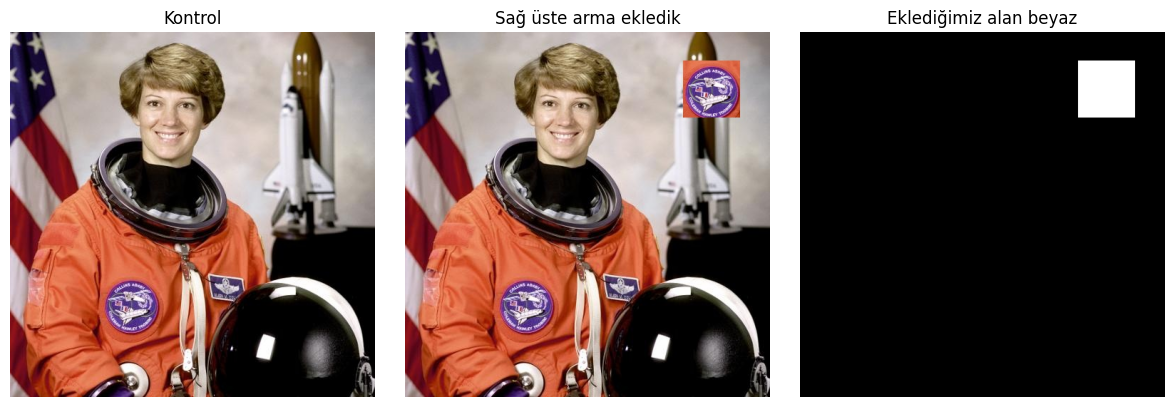

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.title("Kontrol")
plt.axis(False)

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.title("Sağ üste arma ekledik")
plt.axis(False)

plt.subplot(1, 3, 3)
plt.imshow(known_mask, cmap="gray", vmin=0, vmax=255)
plt.title("Eklediğimiz alan beyaz")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "controlled_edit.png")
plt.show()


## 4. Asıl ELA hesabına geçelim / Recompression

Şimdi düzenlenmiş fotoğrafı kalite **90** ile bir kez daha JPEG olarak kaydediyorum. Ardından bu yeni kopyayı geri okuyorum.

Elimizde karşılaştırılacak iki dizi var: `edited_img` yeniden kaydetmeden önceki hali, `recompressed_img` ise sonraki hali.

Henüz farkları bulmadık. Sadece “önce” ve “sonra” görüntülerini hazırladık. Bu adımı görünür tutmak için dosyayı diske yazıyoruz; custom bölümünde aynı JPEG işlemini bellekte yapacağız.


In [8]:
jpeg_quality = 90
recompressed_path = output_dir / "recompressed.jpg"

cv2.imwrite(str(recompressed_path), edited_img, [cv2.IMWRITE_JPEG_QUALITY, jpeg_quality])
recompressed_img = cv2.imread(str(recompressed_path))


### Aynı pikselin iki değerini karşılaştıralım / Absolute difference

`absdiff`, aynı yerdeki iki renk değerinin birbirinden ne kadar uzak olduğunu hesaplıyor. Örneğin 120 ile 115 arasındaki uzaklık **5**. İkisi de 120 ise fark **0**.

Bu işlem bütün piksellerde, üç renk kanalı için ayrı ayrı yapılıyor. Sonuç henüz tek kanallı bir harita değil; içinde üç renk farkı bulunan bir görüntü.

Doğrudan çıkarma yerine `absdiff` kullanmamızın bir nedeni de şu: `uint8` negatif sayıları tutamaz. Mutlak farkı bu fonksiyonla güvenli biçimde alıyoruz.


In [9]:
difference_img = cv2.absdiff(edited_img, recompressed_img)

print("Fark görüntüsünün boyutu:", difference_img.shape)


Fark görüntüsünün boyutu: (512, 512, 3)


### Üç farkı bir sayıyla anlatalım / Average the channels

Bir pikselin mavi, yeşil ve kırmızı kanalında sırasıyla **3, 6 ve 9** fark çıkmış olsun. O pikseli tek sayıyla göstermek için ortalamalarını alıyoruz: `(3 + 6 + 9) / 3 = 6`.

`mean(axis=2)` tam bunu yapıyor. `axis=2`, dizinin renk kanallarını tuttuğu yön. Her pikselde o yöndeki üç sayıyı ortalıyoruz.

Boyutun `(512, 512, 3)` yerine `(512, 512)` olduğuna bak: artık her piksel için bir fark değeri var. Renklendireceğimiz **ELA haritası** bu.


In [10]:
edited_ela = difference_img.mean(axis=2)

print("ELA haritasının boyutu:", edited_ela.shape)
print("Görüntünün ortalama farkı:", round(edited_ela.mean(), 3))


ELA haritasının boyutu: (512, 512)
Görüntünün ortalama farkı: 0.801


### Aynısını kontrol fotoğrafına da yapalım

Sadece düzenlenmiş görüntüye bakarsak normal bir dokuyu yanlış yorumlayabiliriz. Bu yüzden kontrolü de aynı kalite **90** ile yeniden kaydedip farkını alıyorum.

Aynı tarif, aynı ayar: kaydet, oku, mutlak farkı al, kanalları ortala. Böylece birazdan iki haritayı karşılaştırabileceğiz.


In [11]:
cv2.imwrite(str(recompressed_path), original_img, [cv2.IMWRITE_JPEG_QUALITY, jpeg_quality])
recompressed_original = cv2.imread(str(recompressed_path))

original_difference = cv2.absdiff(original_img, recompressed_original)
original_ela = original_difference.mean(axis=2)


## 5. Peki sonuç bize ne gösteriyor? / Read the result

Üst sırada kontrol fotoğrafı ve onun ELA haritası var. Alt sırada arma eklediğimiz fotoğraf ve onun haritası var. Sağ üst köşedeki aynı yere bakıp aradaki davranış farkını incele.

Haritadaki renkler fotoğrafın gerçek renkleri değil. Küçük farkları koyu, büyük farkları açık göstermek için seçtiğimiz bir renk tablosu. Normal arma, yazı ve kenarların da fark üretebildiğine dikkat et.

İki haritada da **0–20** ölçeğini kullanıyoruz. 20'yi aşan farklar da en açık renkte görünüyor. Bu, çizimin sınırı; ölçüm yaparken asıl sayıları kullanmaya devam ediyoruz.

`subplot(2, 2, 1)`, “2 satır ve 2 sütundan oluşan yerleşimin 1. kutusuna çiz” demek.


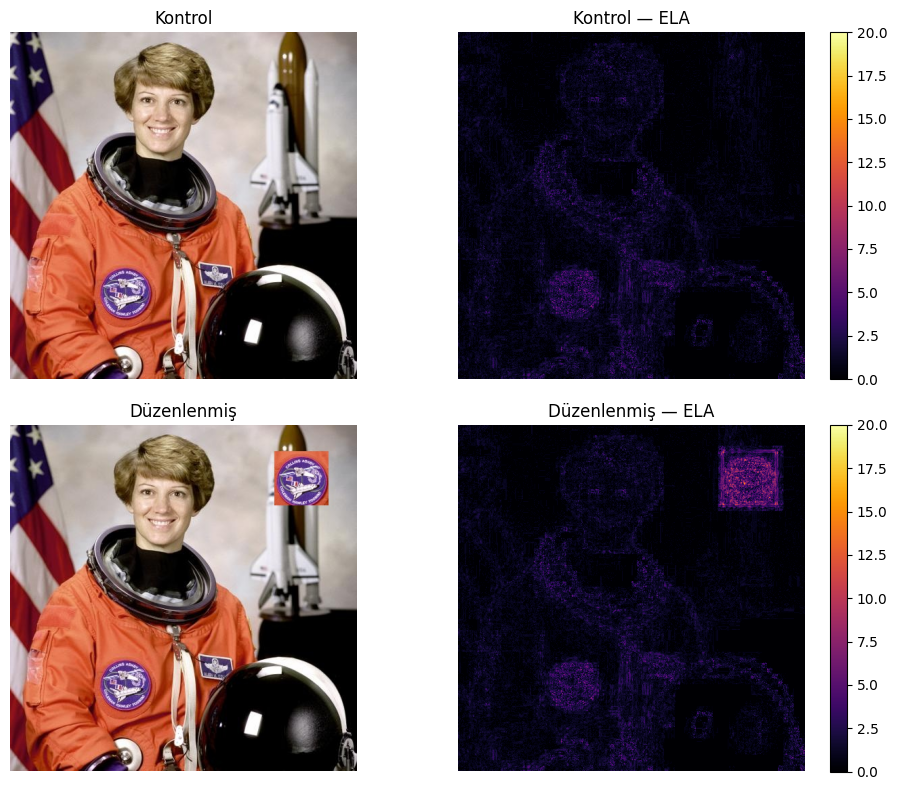

In [12]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.title("Kontrol")
plt.axis(False)

plt.subplot(2, 2, 2)
plt.imshow(original_ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar()
plt.title("Kontrol — ELA")
plt.axis(False)

plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.title("Düzenlenmiş")
plt.axis(False)

plt.subplot(2, 2, 4)
plt.imshow(edited_ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar()
plt.title("Düzenlenmiş — ELA")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "ela_comparison.png")
plt.show()


### Haritanın fotoğrafta nereye denk geldiğini görelim / Overlay

Önce fotoğrafı, sonra aynı yere fark haritasını çiziyorum. `alpha=0.5` üstteki haritayı yarı saydam yapıyor. Böylece parlak alanın hangi nesneye denk geldiğini daha kolay görüyoruz.

Bu yeni bir analiz değil; az önce hesapladığımız sayıları başka bir şekilde gösteriyoruz. Opaklığı değiştirirsen ölçüm aynı kalır, görünüm değişir.


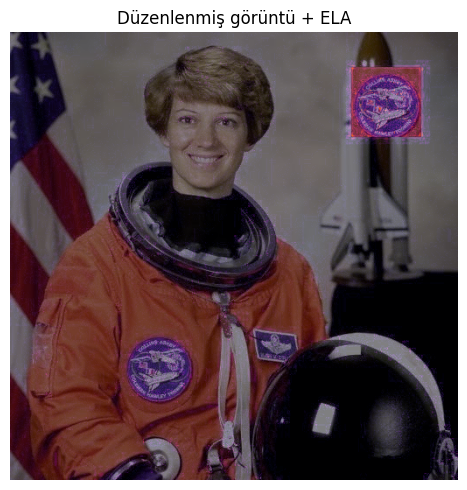

In [13]:
plt.figure(figsize=(5, 5))

plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.imshow(edited_ela, cmap="inferno", vmin=0, vmax=20, alpha=0.5)
plt.title("Düzenlenmiş görüntü + ELA")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "ela_overlay.png")
plt.show()


### Gözle gördüğümüz farkı bir sayıyla da anlatalım

İki haritanın da aynı 80 × 80 piksellik bölgesini alıp ortalamasını hesaplıyorum. Bu bölge, armayı eklediğimiz yer.

Az sonra yazan iki sayı şöyle okunmalı: “Kontrolde bu alandaki ortalama piksel farkı şu, düzenlenmiş örnekte şu.” Büyük olan sayı daha fazla fark demek. **Yüzde, güven puanı veya doğruluk değil.**

Bu alanı biz seçtik; algoritma bulmadı. JPEG'in etkisi seçtiğimiz sınırın biraz dışına da taşabilir. `round(..., 3)` ise sayıyı ekranda üç ondalık basamakla gösteriyor.


In [14]:
original_region = original_ela[40:120, 390:470]
edited_region = edited_ela[40:120, 390:470]

print("Kontrolde bu alanın ortalama farkı:", round(original_region.mean(), 3))
print("Düzenlemeden sonra ortalama fark:", round(edited_region.mean(), 3))

print("Aynı alanı karşılaştırdık. Bunlar ortalama piksel farkları; yüzde değil.")


Kontrolde bu alanın ortalama farkı: 0.556
Düzenlemeden sonra ortalama fark: 4.475
Aynı alanı karşılaştırdık. Bunlar ortalama piksel farkları; yüzde değil.


## 6. Ortak ELA motorunu kullan

Yukarıdaki hücrelerde JPEG sıkıştırmasını ve fark hesabını sırayla gördük. Tekrar çalıştırmak için `image_spatter.ela` içindeki `calculate_ela(img, quality)` fonksiyonunu çağırıyoruz.

Fonksiyon JPEG'i bellekte oluşturup geri açar ve her pikselde üç kanalın ortalama mutlak farkını döndürür. Aynı Python motoru masaüstü uygulamasında ve kontrollü deneyde de kullanılır. Aşağıdaki kontrol, elle hesaplanan harita ile motorun haritasını aynı kalite ayarında piksel piksel karşılaştırır.


In [ ]:
from image_spatter.ela import calculate_ela

np.testing.assert_array_equal(calculate_ela(edited_img, jpeg_quality), edited_ela)


### Süreyi ölç

Başlangıç ve bitiş arasındaki farkı 1000 ile çarparak milisaniyeye çeviriyoruz. Bu süre bellek içi JPEG kodlama, geri açma ve fark hesabını kapsar.


In [ ]:
start_time = perf_counter()

test_ela = calculate_ela(edited_img, 90)

elapsed_ms = (perf_counter() - start_time) * 1000
print("ELA işlem süresi (ms):", round(elapsed_ms, 2))


## 7. Kaliteyi iyice düşürürsek ne olur? / Low-quality comparison

Bu kez **5, 10, 20, 40, 60, 80, 90 ve 95** değerlerini deniyoruz. Böylece yalnızca yüksek kaliteli JPEG'lere bakmakla kalmıyoruz; çok düşük kaliteye indiğimizde ne olduğunu da görebiliyoruz.

- **5, 10, 20:** bu demodaki çok düşük kalite denemeleri.
- **40, 60:** aradaki değişimi görmek için.
- **80, 90, 95:** yüksek kaliteyle karşılaştırmak için.

`for`, her kaliteyi sırayla dener. Her hesap aynı giriş görüntüsünden başlar; önceki JPEG sonucunu bir sonraki denemeye vermiyoruz.

Düşük kalitede fotoğrafın normal bölgelerinde de büyük farklar oluşabilir. Haritanın daha parlak çıkmasını “daha iyi tespit” diye yorumlamayacağız. Bütün haritalarda aynı 0–20 renk ölçeğini koruyoruz; 20 üzerindeki farklar aynı en açık renkte görünür, ölçümlerse ham sayılardan alınır.

English: Include strong JPEG compression to inspect parameter sensitivity. More visible error is not a forgery confidence score.


In [ ]:
qualities = [5, 10, 20, 40, 60, 80, 90, 95]
original_maps = []
edited_maps = []
quality_results = []

for quality in qualities:
    start_time = perf_counter()
    original_map = calculate_ela(original_img, quality)
    original_time = (perf_counter() - start_time) * 1000

    start_time = perf_counter()
    edited_map = calculate_ela(edited_img, quality)
    edited_time = (perf_counter() - start_time) * 1000

    original_mean = original_map[40:120, 390:470].mean()
    edited_mean = edited_map[40:120, 390:470].mean()

    original_maps.append(original_map)
    edited_maps.append(edited_map)
    quality_results.append([quality, original_mean, edited_mean, original_time, edited_time])

    print("JPEG kalitesi:", quality)
    print("  Kontrol alanındaki ortalama fark:", round(original_mean, 3))
    print("  Eklenen alandaki ortalama fark:", round(edited_mean, 3))


### Bütün kalite aralığını birlikte görelim

Grafiğin **üst yarısı kontrol**, **alt yarısı düzenlenmiş** görüntü. Her satırda en fazla dört harita var; böylece düşük kalite değerleri de okunabilir boyutta kalıyor.

`columns` sütun sayısı, `rows` ise her görüntü için gereken satır sayısı. `control_slots`, üst yarının kapladığı kutu sayısı; alt yarıdaki haritaları onun ardından çiziyoruz.

Önce aynı kalite değerinde kontrol ve düzenlenmiş örneği karşılaştır. Sonra kaliteyi 95'ten 5'e doğru düşürdüğümüzde farkların fotoğrafın geneline nasıl yayıldığına bak. Renk ölçeği bütün kutularda aynı.


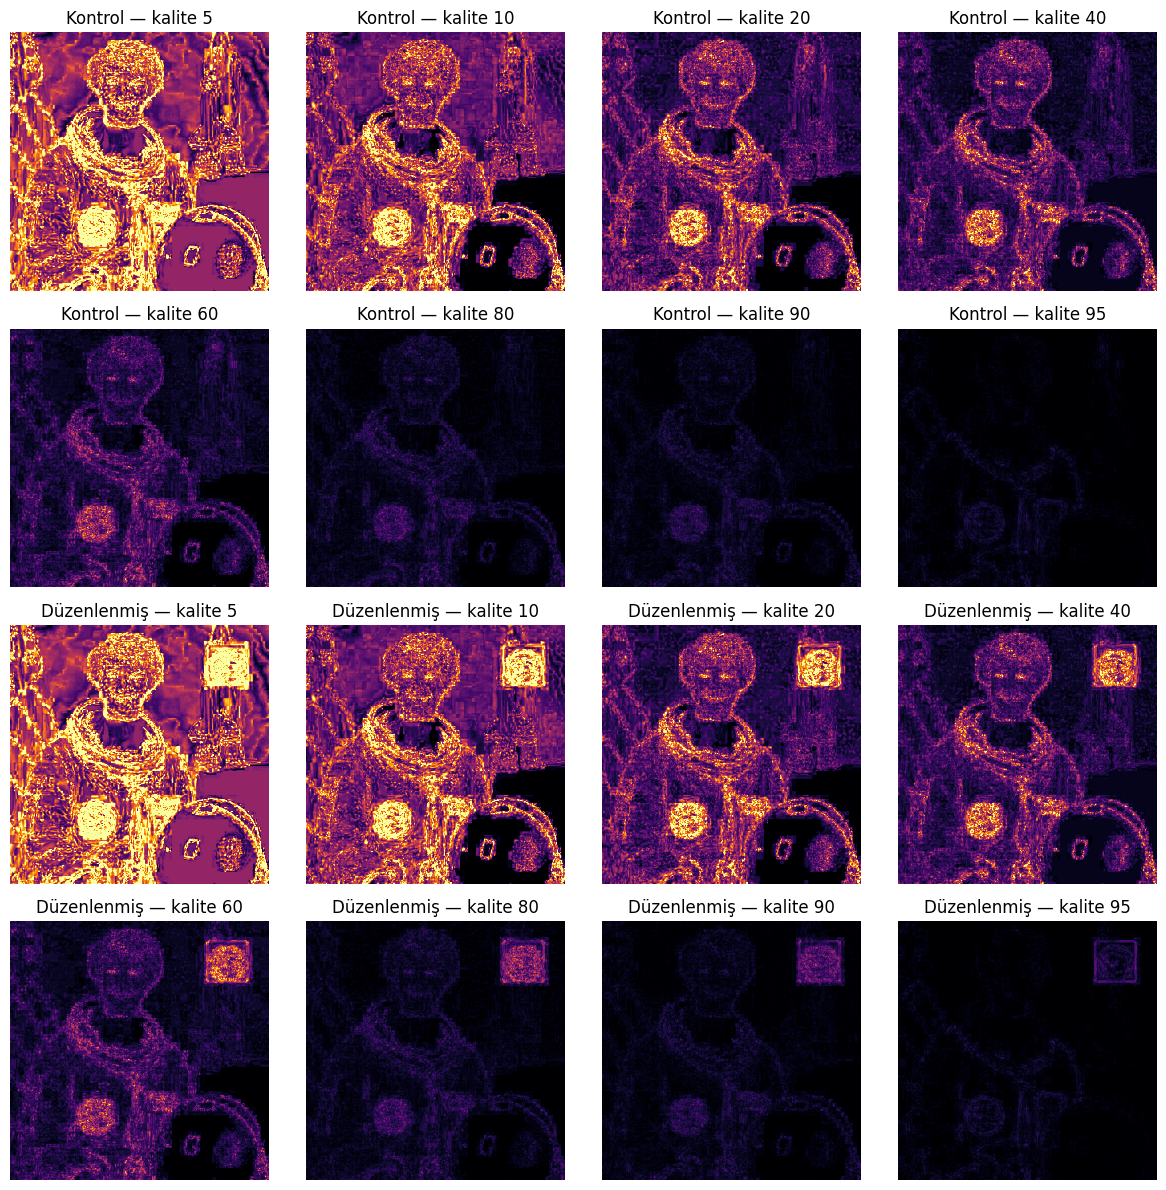

In [18]:
# Each row has at most 4 maps / Her satırda en fazla 4 harita.
columns = min(4, len(qualities))
rows = (len(qualities) + columns - 1) // columns
control_slots = rows * columns

plt.figure(figsize=(3 * columns, 6 * rows))

for i in range(len(qualities)):
    # Upper half / Üst yarı: kontrol görüntüsü.
    plt.subplot(2 * rows, columns, i + 1)
    plt.imshow(original_maps[i], cmap="inferno", vmin=0, vmax=20)
    plt.title(f"Kontrol — kalite {qualities[i]}")
    plt.axis(False)

    # Lower half / Alt yarı: düzenlenmiş görüntü.
    plt.subplot(2 * rows, columns, control_slots + i + 1)
    plt.imshow(edited_maps[i], cmap="inferno", vmin=0, vmax=20)
    plt.title(f"Düzenlenmiş — kalite {qualities[i]}")
    plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "quality_comparison.png")
plt.show()


### Sayılar elimizde kalsın / Save the measurements

Şimdi ölçümleri CSV olarak kaydediyorum. Bunu Excel gibi bir programla da açabilirsin.

Her satırda kalite, kontrol bölgesinin ortalama farkı, düzenlenmiş bölgenin ortalama farkı ve iki işlemin süresi var. Ham sayıları sakladığımız için yalnızca haritanın parlaklığına bağlı kalmadan karşılaştırma yapabiliyoruz.


In [19]:
np.savetxt(
    output_dir / "quality_comparison.csv",
    quality_results,
    delimiter=",",
    header="jpeg_quality,control_region_mean,edited_region_mean,control_time_ms,edited_time_ms",
    comments="",
    fmt="%.3f"
)


## Bu deneyde gerçekten ne yaptık?

Bir arma ekledik ve aynı bölgenin JPEG'e yeniden kaydedilince nasıl tepki verdiğini kontrol görüntüsüyle karşılaştırdık. Fark haritasını, fotoğrafın üstündeki görünümünü ve aynı alanın sayısal ortalamasını inceledik.

Bu özel örneği farklı sıkıştırma geçmişleri oluşturacak şekilde hazırladık. Dolayısıyla sonucu, ELA'nın bütün düzenlemeleri bulduğunu gösteren bir başarı ölçümü olarak sunamayız. Kontroldeki normal dokuların da fark ürettiğini gördük.

Şimdi istersen kendi görüntüne geçebiliriz. Aşağıdaki custom bölümünde bilinen bir düzenleme alanımız yok; elde ettiğimiz farkları görüntünün içeriğiyle birlikte yorumlayacağız.


## 8. Kendi fotoğrafını inceleyelim / Custom image

Bu bölüm kendi başına da çalışır. Buradan başlıyorsan aşağıdaki hücreleri sırayla çalıştır. Bir ayarı değiştirince bu bölümün başından yeniden çalıştırman, eski sonuçlarla yenilerini karıştırmanı önler.

Bu ayrı sürümde başlangıç için projedeki `data/astronaut.png` seçili. Kendi görüntün için `custom_image_path` satırına dosya yolunu yaz. Üstte hazırladığımız düzenlenmiş örneği görmek istersen `outputs/v2_anlatimli/edited.jpg` yolunu seçebilirsin.

Önceki notebook'taki kişisel dosya yolun orada duruyor. Bu yeni sürüm örnek dosyayla çalışsın diye başlangıç yolunu değiştirdim. `None` yazarsan bu bölüm analiz yapmadan geçer.

Burada yapacağımız iş: fotoğrafı aç, ELA'yı hesapla, görüntünün üstüne koy, birkaç kalite dene, istersen bir bölgeyi yakından incele.


In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter
from tempfile import mkdtemp
from PIL import Image, ImageOps


### Hangi ayar ne işe yarıyor? / Settings

Başlamak için yalnızca `custom_image_path` değerini değiştirmen yeterli. Diğer ayarları sonuçları gördükten sonra deneyebilirsin.

| Ayar | Günlük dille anlamı |
|---|---|
| `custom_quality` | Fotoğrafı tekrar JPEG yaparken hangi kaliteyi kullanalım? |
| `custom_display_max` | Farkları ekranda ne kadar belirgin gösterelim? Düşürürsen harita daha parlak görünür. |
| `custom_overlay_alpha` | Haritayı fotoğrafın üstüne ne kadar opak çizelim? 0 görünmez, 1 tamamen görünür. |
| `custom_qualities` | Karşılaştırmak istediğin JPEG kalite değerleri. |
| `custom_roi` | Yakından bakmak istediğin dikdörtgen: `(x, y, genişlik, yükseklik)`. |
| `custom_save_outputs` | Görselleri ve ölçümleri dosyaya da kaydedelim mi? |

**Quality** hesapladığımız farkı değiştirir. **Display max** ve **alpha** sadece gösterme biçimini değiştirir. Bu ayrımı özellikle koruyoruz.


In [21]:
custom_image_path = "data/astronaut.png"
custom_quality = 80

custom_display_max = 20
custom_overlay_alpha = 0.5
custom_qualities = [5, 10, 20, 40, 60, 80, 90, 95]
custom_roi = None  # Optional region / Bölge: (x, y, width, height)

custom_save_outputs = True
custom_output_root = Path("outputs") / "v2_anlatimli" / "custom"


### Fotoğrafı düzgün açalım / Load the file

Burada Pillow kullanıyorum; çünkü telefon fotoğraflarındaki yön bilgisini de okuyabiliyor. Fotoğrafı doğru yönde açıp OpenCV için renk sırasını hazırlıyoruz. Analizden önce boyutunu küçültmüyoruz.

Dosyanın gerçek formatını da öğreniyoruz. Adı `.jpg` ile bitse bile içerik başka format olabilir. Girdi JPEG değilse yine fark hesaplayabiliriz; ancak bu, o görüntünün JPEG'e çevrilirken verdiği tepki olur.

Saydam alanları olan bir görüntü açarsan bunları beyaz zeminle birleştirir ve bunu ekrana yazarız. ELA hesabını bu renkli görünüm üzerinde yaparız. [EXIF yön bilgisi hakkında Pillow belgesi](https://pillow.readthedocs.io/en/stable/reference/ImageOps.html#PIL.ImageOps.exif_transpose).


In [22]:
# Reset results / Önceki çalıştırmanın sonucunu kullanma.
custom_img = None
custom_ela = None
custom_figure = None
custom_quality_figure = None
custom_roi_figure = None
custom_quality_rows = []
custom_roi_row = []

if custom_image_path is None:
    print("No image selected / custom_image_path değerine dosya yolu yaz.")
else:
    custom_path = Path(custom_image_path).expanduser()
    if not custom_path.is_file():
        raise FileNotFoundError("Image not found / Dosya yolunu kontrol et.")

    with Image.open(custom_path) as image_file:
        custom_format = image_file.format
        oriented_img = ImageOps.exif_transpose(image_file)

        if oriented_img.mode not in ("1", "L", "LA", "P", "RGB", "RGBA", "CMYK", "YCbCr"):
            raise ValueError("Use an 8-bit image / Bu demo için 8-bit JPEG veya PNG kullan.")

        has_alpha = "A" in oriented_img.getbands() or "transparency" in image_file.info
        if has_alpha:
            rgba_img = oriented_img.convert("RGBA")
            white_background = Image.new("RGBA", rgba_img.size, "white")
            oriented_img = Image.alpha_composite(white_background, rgba_img)
            print("Transparency / Saydam alanlar beyaz zeminle birleştirildi.")

        custom_rgb = np.array(oriented_img.convert("RGB"))

    custom_img = cv2.cvtColor(custom_rgb, cv2.COLOR_RGB2BGR)
    print("File / Dosya:", custom_path.name)
    print("Format:", custom_format)
    print("Size / Boyut (height, width, channels):", custom_img.shape)

    if custom_format != "JPEG":
        print("Non-JPEG input / Bu harita, girişin JPEG'e yeniden kodlanma farkını gösterir.")


File / Dosya: astronaut.png
Format: PNG
Size / Boyut (height, width, channels): (512, 512, 3)
Non-JPEG input / Bu harita, girişin JPEG'e yeniden kodlanma farkını gösterir.


### Aynı ELA tarifini bu kez bellekte yapalım

Mantık değişmedi: JPEG'e çevir, tekrar piksel olarak aç, mutlak farkı al, üç kanalın ortalamasını hesapla.

Bu sefer `imencode` JPEG verisini bir dosyaya yazmadan bellekte oluşturuyor. `imdecode` da o veriyi tekrar görüntüye çeviriyor. Daha önce kullandığımız `imwrite` / `imread` çiftinin dosya oluşturmadan yapılan hali gibi düşünebilirsin.

Fonksiyonun verdiği sonuç yine ham piksel farkları. Custom bölümünde ölçtüğümüz süre bu bellek içi JPEG işlemini ve fark hesabını içeriyor; dosyayı ilk açma, çizme ve sonuç kaydetme süresini içermiyor.

Bu hücre ortak Python motorunu içe aktarır. Bu bölümü üstteki hücreleri çalıştırmadan kullanabilirsin.


In [ ]:
from image_spatter.ela import calculate_ela as calculate_custom_ela


### Şimdi hesaplayalım / Run the analysis

Birazdan birkaç sayı göreceksin. **Mean error**, bütün piksellerin ortalama farkı. **P95 / 95th percentile** ise piksellerin yaklaşık %95'inin eşit veya altında kaldığı fark seviyesi.

Örneğin ortalama farkın 4 çıkması, dosyanın %4 sahte olduğu anlamına gelmez. Yalnızca bu kalite ayarında renk değerlerinin ne kadar değiştiğini anlatır.

Ölçümleri ham haritadan alıyoruz. Ekrandaki haritayı daha parlak göstermiş olman bu sayıları değiştirmez.


In [24]:
if custom_img is not None:
    if not np.isfinite(custom_display_max) or custom_display_max <= 0:
        raise ValueError("Display max / Görünüm üst sınırı sıfırdan büyük olmalı.")
    if not 0 <= custom_overlay_alpha <= 1:
        raise ValueError("Overlay alpha / Opaklık 0 ile 1 arasında olmalı.")

    start_time = perf_counter()
    custom_ela = calculate_custom_ela(custom_img, custom_quality)
    custom_elapsed_ms = (perf_counter() - start_time) * 1000

    print("JPEG quality / Kalite:", custom_quality)
    print("Mean error / Ortalama fark:", round(custom_ela.mean(), 3))
    print("95th percentile / Yüzde 95 eşiği:", round(np.percentile(custom_ela, 95), 3))
    print("Analysis time / Süre (ms):", round(custom_elapsed_ms, 2))


JPEG quality / Kalite: 80
Mean error / Ortalama fark: 2.948
95th percentile / Yüzde 95 eşiği: 8.667
Analysis time / Süre (ms): 3.05


### Üç görüntüyü birlikte okuyalım / Input, ELA, overlay

Solda seçtiğin fotoğraf var. Ortada yalnızca fark haritası var. Sağda ise o harita fotoğrafın üzerine çizilmiş halde; bu son görünüme **overlay** diyoruz.

Bir parlaklığa bakarken fotoğrafın aynı yerine de bak. Orada normal bir yazı, keskin kenar veya yoğun doku var mı? Sonuçları böyle içerikle birlikte inceleyeceğiz.

Ortak renk ölçeğinin üstündeki değerler aynı en parlak renkte görünür. Bu sınır yalnızca görüntüleme içindir. Seçtiğin fotoğrafı “orijinal olduğu doğrulanmış dosya” olarak kabul etmiyoruz; o bizim analiz girdimiz.


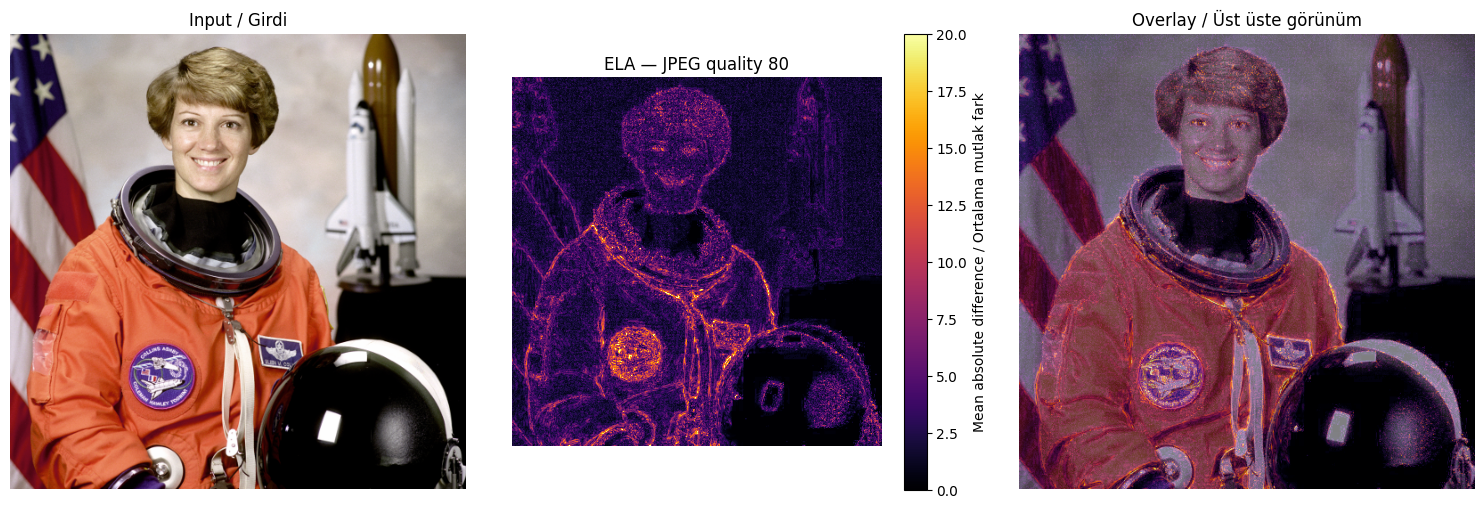

In [25]:
if custom_ela is not None:
    custom_figure = plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(custom_rgb)
    plt.title("Input / Girdi")
    plt.axis(False)

    plt.subplot(1, 3, 2)
    plt.imshow(custom_ela, cmap="inferno", vmin=0, vmax=custom_display_max)
    plt.colorbar(label="Mean absolute difference / Ortalama mutlak fark")
    plt.title(f"ELA — JPEG quality {custom_quality}")
    plt.axis(False)

    plt.subplot(1, 3, 3)
    plt.imshow(custom_rgb)
    plt.imshow(custom_ela, cmap="inferno", vmin=0, vmax=custom_display_max,
               alpha=custom_overlay_alpha)
    plt.title("Overlay / Üst üste görünüm")
    plt.axis(False)

    plt.tight_layout()
    plt.show()


### Bir de başka kalitelerde bakalım / Quality comparison

Aşağıdaki döngü, aynı fotoğrafı birkaç kalite ayarıyla ayrı ayrı yeniden sıkıştırıyor. Her deneme aynı girişten başlıyor; önceki denemenin sonucunu devam ettirmiyoruz.

Renk ölçeği hepsinde aynı kalıyor. Böylece bir bölgenin davranışı ayarla birlikte değişiyor mu, görebiliyoruz. Bu işlem dosyanın ilk kaydedildiği kaliteyi tahmin ettiğimiz anlamına gelmiyor.

Düşük kalite aralığı da listede: **5, 10, 20, 40, 60, 80, 90, 95**. Aynı fotoğrafı her ayarda yeniden inceliyoruz. Haritalar en fazla dört sütunla gösterilir. Çok düşük kalite, normal dokularda da fark oluşturabilir; parlaklık tespit başarısı değildir.

English: Low-quality presets are included; all maps keep the same display scale.


Q=5: mean=11.413, P95=28.333, time=2.92 ms
Q=10: mean=7.734, P95=21.000, time=2.82 ms
Q=20: mean=5.481, P95=16.333, time=2.88 ms
Q=40: mean=4.333, P95=13.000, time=2.96 ms
Q=60: mean=3.666, P95=11.000, time=3.05 ms
Q=80: mean=2.948, P95=8.667, time=3.17 ms
Q=90: mean=2.371, P95=6.333, time=3.37 ms
Q=95: mean=1.950, P95=5.000, time=3.59 ms


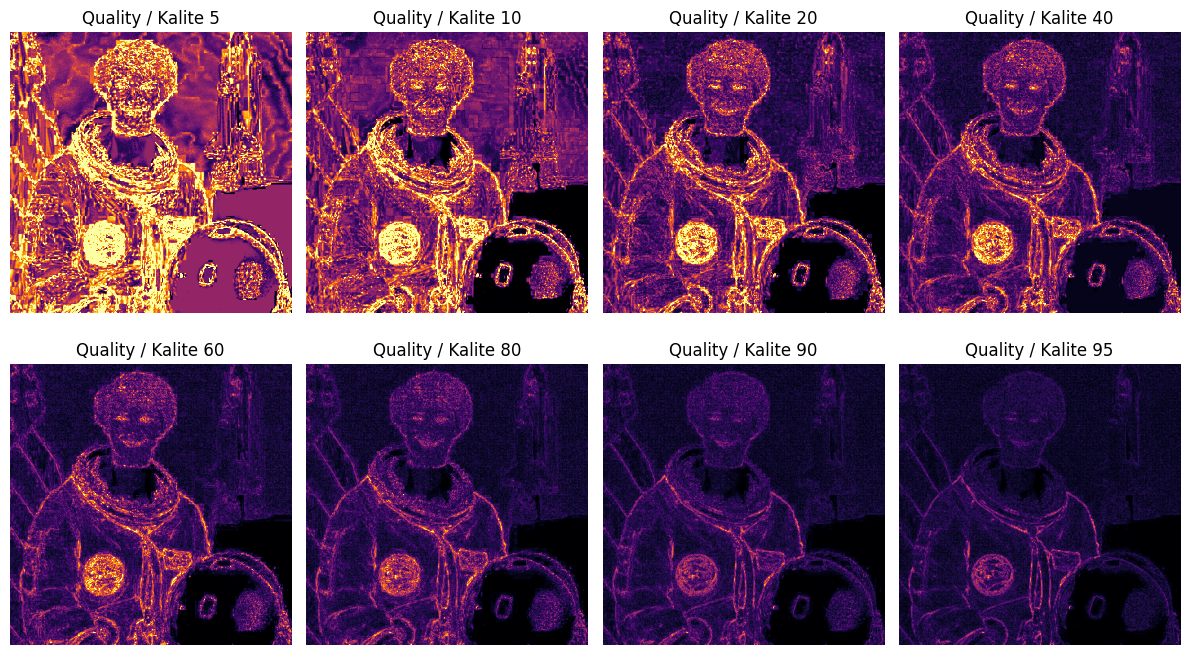

In [26]:
custom_quality_rows = []
custom_quality_figure = None

if custom_ela is not None:
    if not custom_qualities:
        raise ValueError("Quality list / En az bir kalite değeri yaz.")

    columns = min(4, len(custom_qualities))
    rows = (len(custom_qualities) + columns - 1) // columns
    custom_quality_figure = plt.figure(figsize=(3 * columns, 3.5 * rows))

    for i in range(len(custom_qualities)):
        quality = custom_qualities[i]
        start_time = perf_counter()
        quality_map = calculate_custom_ela(custom_img, quality)
        elapsed_ms = (perf_counter() - start_time) * 1000

        mean_error = float(quality_map.mean())
        p95_error = float(np.percentile(quality_map, 95))
        custom_quality_rows.append([quality, mean_error, p95_error, elapsed_ms])

        plt.subplot(rows, columns, i + 1)
        plt.imshow(quality_map, cmap="inferno", vmin=0, vmax=custom_display_max)
        plt.title(f"Quality / Kalite {quality}")
        plt.axis(False)
        print(f"Q={quality}: mean={mean_error:.3f}, P95={p95_error:.3f}, time={elapsed_ms:.2f} ms")

    plt.tight_layout()
    plt.show()


### Şu köşeye biraz yakından bakalım / ROI

**ROI — Region of Interest**, yalnızca “ilgilenmek istediğimiz bölge” demek. Ayarlardaki `custom_roi` değerine `(100, 80, 120, 100)` yazarsan soldan 100, üstten 80 piksel ilerleyip 120 piksel genişliğinde, 100 piksel yüksekliğinde bir alan seçmiş olursun.

Yeşil kutuyu biz bu koordinatlarla çiziyoruz. Algoritmanın bulduğu bir şüpheli alan değil.

Önce bütün fotoğrafın ELA'sını hesaplayıp sonra bu haritadan parçayı alıyoruz. Parçayı ayrı JPEG yapmıyoruz; yoksa ölçümün başlangıç koşullarını da değiştirmiş olurduk. Yakın görünümü istemiyorsan `None` bırak.


In [27]:
custom_roi_row = []
custom_roi_figure = None

if custom_ela is not None and custom_roi is not None:
    if not isinstance(custom_roi, (tuple, list)) or len(custom_roi) != 4:
        raise ValueError("ROI: (x, y, width, height) şeklinde dört sayı yaz.")
    if not all(type(value) is int for value in custom_roi):
        raise ValueError("ROI coordinates / Bölge koordinatları tam sayı olmalı.")

    x, y, width, height = custom_roi
    image_height, image_width = custom_img.shape[:2]
    if x < 0 or y < 0 or width <= 0 or height <= 0:
        raise ValueError("ROI başlangıcı negatif olamaz; genişlik ve yükseklik pozitif olmalı.")
    if x + width > image_width or y + height > image_height:
        raise ValueError("ROI is outside the image / Bölge görüntünün dışına taşıyor.")

    roi_rgb = custom_rgb[y:y + height, x:x + width]
    roi_ela = custom_ela[y:y + height, x:x + width]
    custom_roi_row = [x, y, width, height, float(roi_ela.mean())]

    roi_preview = custom_rgb.copy()
    cv2.rectangle(roi_preview, (x, y), (x + width - 1, y + height - 1), (0, 255, 0), 2)
    custom_roi_figure = plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(roi_preview)
    plt.title("Selected region / Seçilen alan")
    plt.axis(False)

    plt.subplot(1, 3, 2)
    plt.imshow(roi_rgb)
    plt.title("Crop / Yakın görünüm")
    plt.axis(False)

    plt.subplot(1, 3, 3)
    plt.imshow(roi_ela, cmap="inferno", vmin=0, vmax=custom_display_max)
    plt.colorbar()
    plt.title("ROI — ELA")
    plt.axis(False)

    plt.tight_layout()
    plt.show()
    print("ROI mean error / Bölgenin ortalama farkı:", round(roi_ela.mean(), 3))


### Sonuçları saklayalım / Export

Kaydetme açıksa her çalıştırmada bu sürümün custom klasöründe yeni bir sonuç klasörü açılır. Önceki sonucun üstüne yazmak yerine ayrı bir deneme saklamış oluruz.

PNG'ler gördüğün görseller. CSV'ler sayısal ölçümler. `ela_raw.npy` ise renk veya parlaklık ayarı uygulanmamış ham ELA dizisi; Python'da tekrar hesap yapmak istersen onu kullanabilirsin.

Bölge seçtiysen onun yakın görünümü de kaydedilir. `summary.txt` dosyasında girişin adı ve kullandığın ayarlar bulunur. Giriş dosyasının kendisini değiştirmiyoruz, EXIF içeriğini de özete eklemiyoruz.


In [28]:
if custom_ela is not None and custom_save_outputs:
    image_output_dir = custom_output_root / custom_path.stem
    image_output_dir.mkdir(parents=True, exist_ok=True)
    # mkdtemp creates a new folder / Her çalıştırmada ayrı klasör.
    custom_run_dir = Path(mkdtemp(prefix=f"q{custom_quality}_", dir=image_output_dir))

    custom_figure.savefig(custom_run_dir / "comparison.png", dpi=120)
    plt.imsave(custom_run_dir / "ela_heatmap.png", custom_ela,
               cmap="inferno", vmin=0, vmax=custom_display_max)
    np.save(custom_run_dir / "ela_raw.npy", custom_ela)

    if custom_quality_figure is not None:
        custom_quality_figure.savefig(custom_run_dir / "quality_comparison.png", dpi=120)
        np.savetxt(custom_run_dir / "quality_comparison.csv", custom_quality_rows,
                   delimiter=",", fmt="%.4f", comments="",
                   header="jpeg_quality,mean_error,p95_error,analysis_time_ms")

    if custom_roi_figure is not None:
        custom_roi_figure.savefig(custom_run_dir / "roi.png", dpi=120)
        np.savetxt(custom_run_dir / "roi.csv", [custom_roi_row], delimiter=",",
                   fmt="%.4f", comments="", header="x,y,width,height,mean_error")

    summary = (
        f"Input filename: {custom_path.name}\nFormat: {custom_format}\n"
        f"Size (height, width): {custom_img.shape[:2]}\nJPEG quality: {custom_quality}\n"
        f"Display max: {custom_display_max}\nOverlay alpha: {custom_overlay_alpha}\n"
        f"Mean absolute error: {custom_ela.mean():.4f}\n"
        f"Analysis time, memory JPEG round trip (ms): {custom_elapsed_ms:.2f}\n"
        "ELA values are pixel differences, not forgery probabilities.\n"
    )
    (custom_run_dir / "summary.txt").write_text(summary, encoding="utf-8")
    print("Saved / Kaydedildi:", custom_run_dir)


Saved / Kaydedildi: /Users/deniz/Image Processing/Image_Processing_Project/outputs/v2_anlatimli/custom/astronaut/q80_qqrryrpo


### Kendi fotoğrafında sonuca nasıl yaklaşacaksın?

Önce fotoğrafın kendisine, sonra haritadaki farklara bak. Normal kenarların ve dokuların da fark ürettiğini hatırla. İlgini çeken alanı overlay veya ROI ile inceleyip birkaç kalite ayarında davranışına bakabilirsin.

Bir bölgenin açık çıkması incelemeye değer bir fark gösterir. Koyu çıkması da dosyanın özgünlüğünü doğrulamaz. Elimizde bu fotoğrafın bilinen düzenleme maskesi olmadığı için tespit doğruluğunu hesaplayamayız.

Raporlarken gözlemini somut anlat: “Şu bölgede, şu kalite ayarında daha yüksek yeniden sıkıştırma farkı gördüm.” Bu, eldeki ölçümün gerçekten söylediği şey.
